# FlowSOM: Dateinamen, Kohorten und unabhängige Einzelproben
Vollständiger Workflow für kompensierte Kaluza-Ereignislisten. 

## Ordnerstruktur
```
Projekt/
  FlowSOM_Dateinamen_Kohorten.ipynb
  input_events/
    CAF/
      female_1year_skin_0Gy_noTNF/
        original_datei_1.csv
        original_datei_2.csv
        ...
      male_1year_skin_0Gy_noTNF/
        original_datei_5.csv
        ...
    Intra/                       
      female_1year_skin_0Gy_noTNF/
        ...
      male_1year_skin_0Gy_noTNF/
        ...
  flowsom_results_dateinamen/     # wird automatisch erzeugt
```




Installation:
`python -m pip install flowsom anndata numpy pandas matplotlib seaborn umap-learn scipy statsmodels jupyter`



In [1]:
from pathlib import Path
import json
import warnings
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import flowsom as fs
from umap import UMAP
from IPython.display import display

for package in ["flowsom", "anndata", "numpy", "pandas", "umap-learn"]:
    print(package, importlib.metadata.version(package))
import uuid
import textwrap
import math


flowsom 0.2.2
anndata 0.12.19
numpy 2.4.6
pandas 2.3.3
umap-learn 0.5.12


In [10]:
DATA_DIR = Path("input_events")
OUTPUT_DIR = Path("flowsom_results_dateinamen")
SIGNAL = "A"  # alternativ "H"
SEED = 42
N_METACLUSTERS = 6  # explorative Auflösung, keine Annahme von sechs echten Subtypen
SOM_X = SOM_Y = 6
MAX_TRAIN_PER_SAMPLE = 10_000
UMAP_MAX_CELLS = 10_000
PILOT_COFACTOR = 1_000.0

PANELS = {
    "CAF": {
        "pattern": "*CAF*.csv",
        "markers": {"CD95": "CD95 FITC", "CD87": "CD87 APC",
                    "Ly6C": "Ly-6C APC-A700", "CD39": "CD39 Violet610",
                    "CD44": "CD44 ECD", "CD49b": "CD49b PC7"},
    },
    "Intra": {
        "pattern": "*Intra*.csv",
        "markers": {"alphaSMA": "aSMA FITC", "Ly6AE": "Ly-6A/E PerCP",
                    "FAP": "FAP APC", "CD39": "CD39 Violet610",
                    "CD140a": "CD140a PE"},
    },
}
# Optional: fixe Cofaktoren pro Panel und Marker; sonst PILOT_COFACTOR.
COFACTORS = {"CAF": {}, "Intra": {}}


COHORT_A = "female_1year_skin_0Gy_noTNF"
COHORT_B = "male_1year_skin_0Gy_noTNF"
CONFIRM_INDEPENDENT_FILES = True  # nach Prüfung True: eine Datei = unabhängige biologische Probe
PLOT_COLUMNS = 2
ALREADY_TRANSFORMED = False  # Standard wie Original: arcsinh wird einmal angewendet


## 1. Automatische Dateizuordnung
Die Tabelle muss die richtigen Kohorten und alle erwarteten Dateien enthalten. 

In [11]:
assert DATA_DIR.is_dir(), f"Eingabeordner fehlt: {DATA_DIR.resolve()}"
assert not OUTPUT_DIR.resolve().is_relative_to(DATA_DIR.resolve()), "Ausgabe außerhalb Eingabe ablegen."
rows=[]
for panel in PANELS:
    for path in sorted((DATA_DIR/panel).rglob("*.csv")):
        rel=path.relative_to(DATA_DIR/panel)
        if len(rel.parts)<2: raise ValueError(f"Kohortenordner fehlt: {path}")
        if any(w in path.stem.lower() for w in ["unstained","fmo","isotype"]):
            raise ValueError(f"Kontrolldatei entfernen: {path}")
        rows.append(dict(panel=panel,cohort=rel.parts[0],filename=path.name,
                         relative_path=path.relative_to(DATA_DIR).as_posix()))
assert rows, "Keine CSVs in DATA_DIR/Panel/Kohorte gefunden."
file_index=pd.DataFrame(rows).sort_values(["panel","cohort","filename"]).reset_index(drop=True)
assert not file_index.duplicated(["panel","filename"]).any(), "Dateinamen innerhalb eines Panels müssen eindeutig sein."
display(file_index)
display(file_index.groupby(["panel","cohort"]).size().rename("n_Dateien").to_frame())
RUN_ID=uuid.uuid4().hex
RUN_DIR=OUTPUT_DIR / (pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")+"_"+RUN_ID[:6])
RUN_DIR.mkdir(parents=True,exist_ok=False)
file_index.to_csv(RUN_DIR/"file_index.csv",index=False)
print("Aktueller Ausgabeordner:",RUN_DIR.resolve())

,panel,cohort,filename,relative_path
0,CAF,female_1year_skin_0Gy_noTNF,female1year_1st_CAF.csv,CAF/female_1year_skin_0Gy_noTNF/female1year_1s...
1,CAF,female_1year_skin_0Gy_noTNF,female1year_2nd_CAF.csv,CAF/female_1year_skin_0Gy_noTNF/female1year_2n...
2,CAF,female_1year_skin_0Gy_noTNF,female1year_3rd_CAF.csv,CAF/female_1year_skin_0Gy_noTNF/female1year_3r...
3,CAF,female_1year_skin_0Gy_noTNF,female1year_4th_CAF.csv,CAF/female_1year_skin_0Gy_noTNF/female1year_4t...
4,CAF,male_1year_skin_0Gy_noTNF,male1year_1st_CAF.csv,CAF/male_1year_skin_0Gy_noTNF/male1year_1st_CA...
5,CAF,male_1year_skin_0Gy_noTNF,male1year_2nd_CAF.csv,CAF/male_1year_skin_0Gy_noTNF/male1year_2nd_CA...
6,CAF,male_1year_skin_0Gy_noTNF,male1year_3rd_CAF.csv,CAF/male_1year_skin_0Gy_noTNF/male1year_3rd_CA...


n_Dateien
panel cohort                                
CAF   female_1year_skin_0Gy_noTNF          4
      male_1year_skin_0Gy_noTNF            3

Aktueller Ausgabeordner: /home/tom/Desktop/Experiments/Clustering/male_female_1year_0Gy_-TNF/flowsom_results_dateinamen/20261113_130210_3e66af


## 2. Import und Transformation
Alle Originalmarker und CD90 bleiben erhalten. Die Histogramme sind nach Kohorte getrennt, Farben bezeichnen Dateinamen. Nichtendliche/ungültige Werte führen zum Abbruch statt stiller Änderungen am Nenner.

n_Zellen
cohort                      filename                         
female_1year_skin_0Gy_noTNF female1year_1st_CAF.csv     11815
                            female1year_2nd_CAF.csv     23710
                            female1year_3rd_CAF.csv      5186
                            female1year_4th_CAF.csv     15368
male_1year_skin_0Gy_noTNF   male1year_1st_CAF.csv       41920
                            male1year_2nd_CAF.csv       33259
                            male1year_3rd_CAF.csv       41900

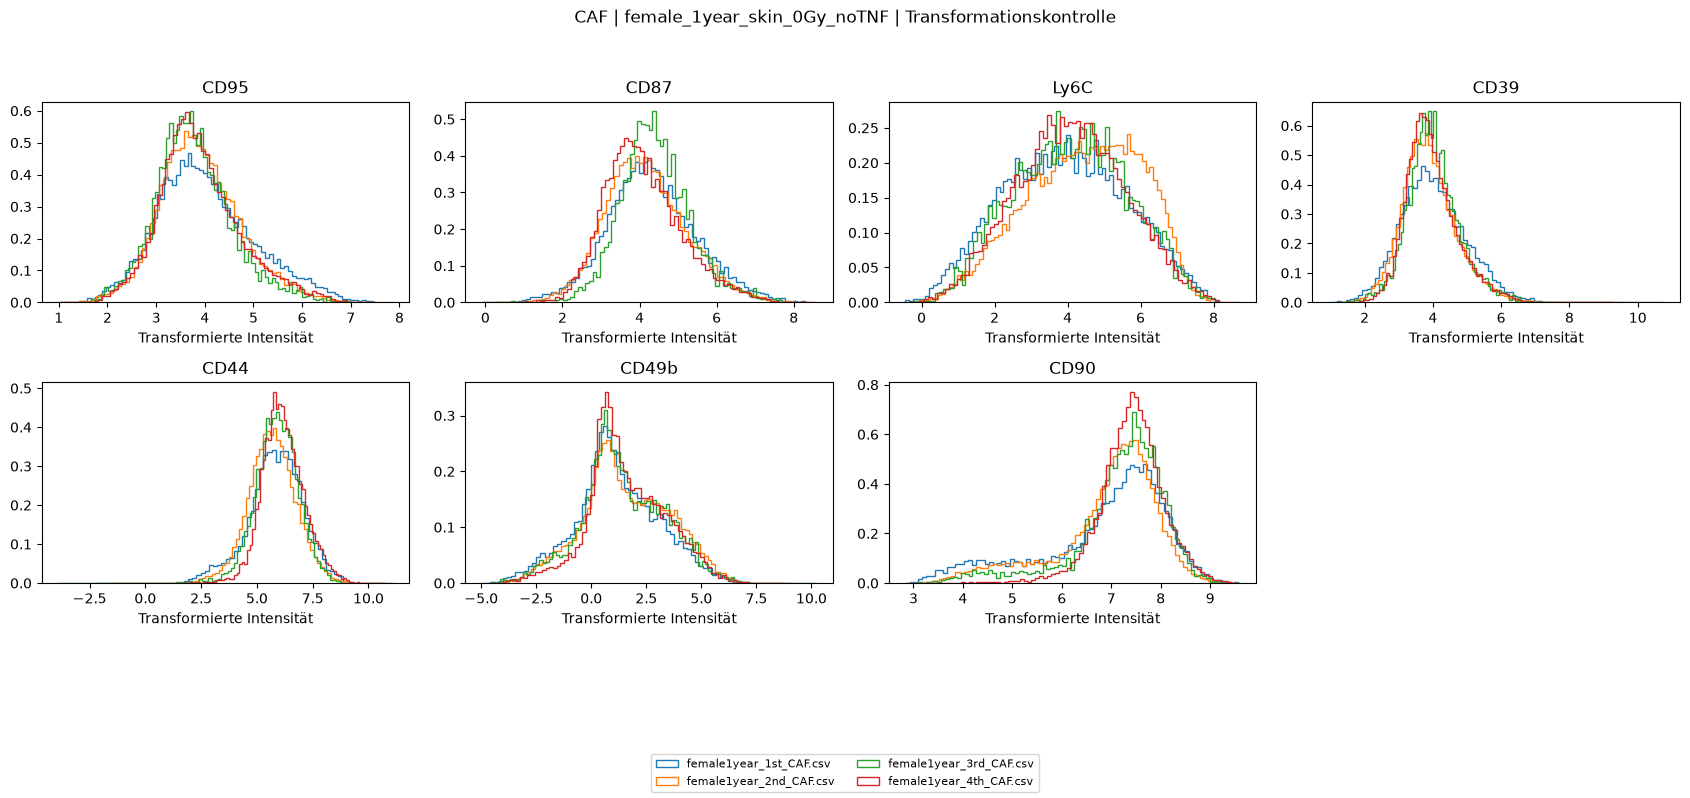

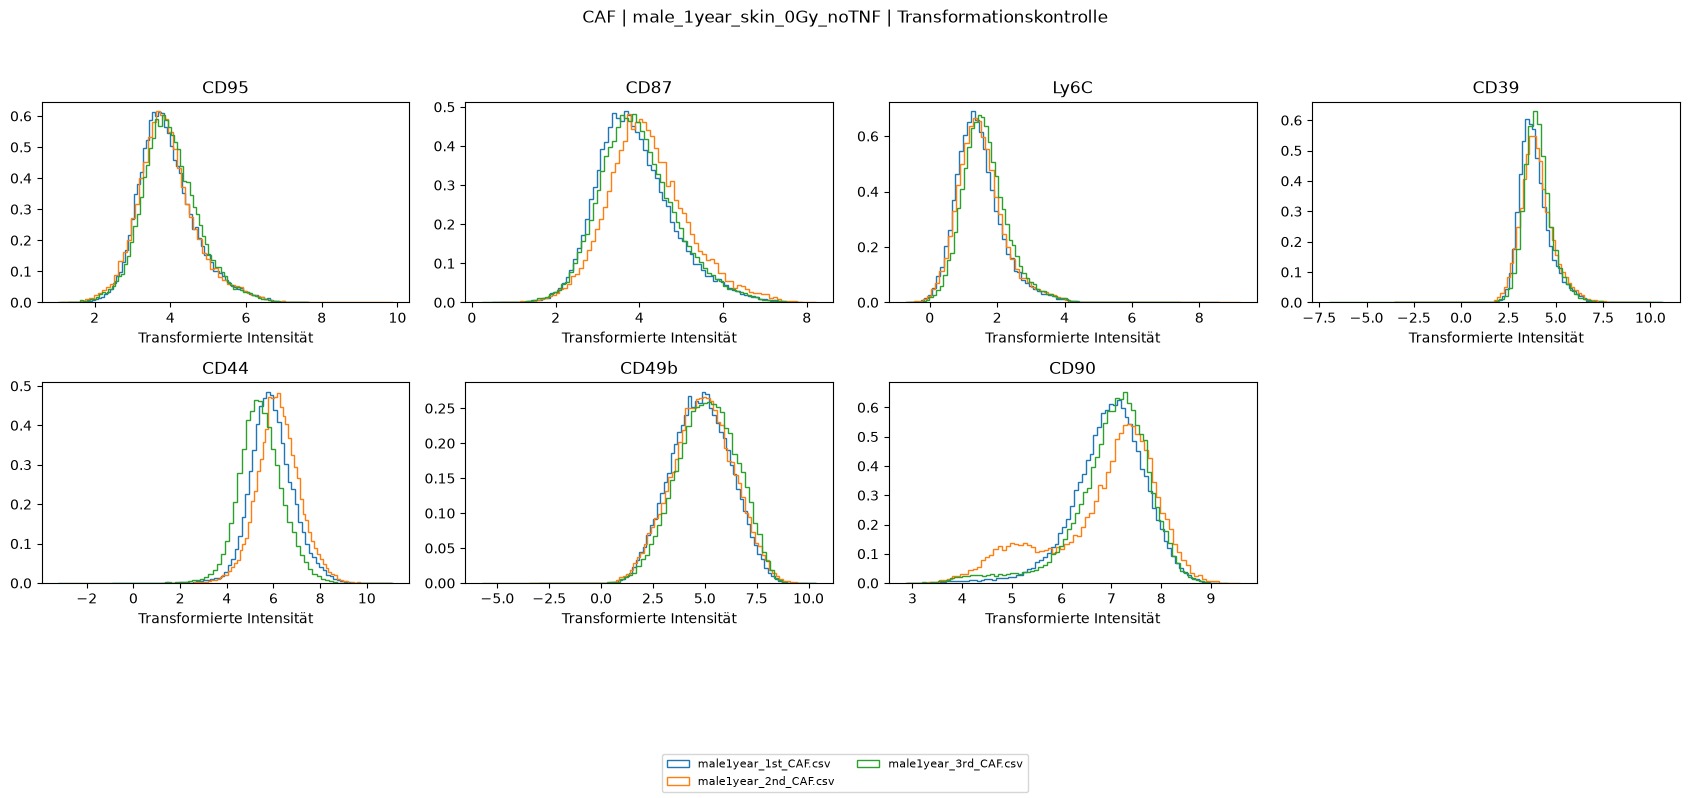

Überspringe nicht vorhandenes Panel: Intra


In [12]:
def load_panel(panel, config):
    files = [DATA_DIR / p for p in file_index.loc[file_index.panel == panel, "relative_path"]]
    if not files:
        raise FileNotFoundError(f"Keine Dateien für {panel}: {config['pattern']}")
    mapping = {f"{channel}-{SIGNAL}": marker
               for marker, channel in config["markers"].items()}
    mapping[f"CD90.2 PB450-{SIGNAL}"] = "CD90"
    tables, qc = [], []
    for path in files:
        if any(word in path.name.lower() for word in ["unstained", "fmo", "isotype"]):
            raise ValueError(f"Kontrolldatei nicht mitclustern: {path.name}")
        raw = pd.read_csv(path, sep=";", decimal=",", encoding="utf-8-sig")
        raw.columns = raw.columns.str.strip()
        if raw.columns.duplicated().any():
            raise ValueError(f"{path.name}: doppelte Spaltennamen")
        missing = set(mapping) - set(raw.columns)
        if missing:
            raise ValueError(f"{path.name}: Kanäle fehlen: {sorted(missing)}")
        numeric = raw.apply(pd.to_numeric, errors="raise")
        if numeric.empty or not np.isfinite(numeric.to_numpy()).all():
            raise ValueError(f"{path.name}: leere oder nicht-endliche Ereignisdaten")
        selected = numeric[list(mapping)].rename(columns=mapping)
        selected.insert(0, "event_id", np.arange(1, len(selected)+1))
        selected.insert(0, "filename", path.name)
        tables.append(selected)
        for channel in mapping:
            v = numeric[channel]
            qc.append({"filename": path.name, "channel": channel,
                       "n_events": len(v), "negative_fraction": float((v < 0).mean()),
                       "q01": v.quantile(.01), "median": v.median(),
                       "q99": v.quantile(.99)})
    return pd.concat(tables, ignore_index=True), pd.DataFrame(qc)


def transform_panel(raw, panel, marker_names):
    transformed = raw.copy()
    if ALREADY_TRANSFORMED: return transformed
    for marker in marker_names + ["CD90"]:
        cofactor = float(COFACTORS[panel].get(marker, PILOT_COFACTOR))
        if not np.isfinite(cofactor) or cofactor <= 0:
            raise ValueError(f"Ungültiger Cofaktor für {panel}/{marker}")
        transformed[marker] = np.arcsinh(raw[marker].to_numpy() / cofactor)
    return transformed



raw_panels, transformed_panels = {}, {}
for panel,config in PANELS.items():
    if panel not in set(file_index.panel):
        print("Überspringe nicht vorhandenes Panel:",panel); continue
    raw,qc=load_panel(panel,config)
    meta=file_index[file_index.panel==panel][["filename","cohort"]]
    raw=raw.merge(meta,on="filename",validate="many_to_one")
    transformed=transform_panel(raw,panel,list(config["markers"]))
    raw_panels[panel],transformed_panels[panel]=raw,transformed
    folder=RUN_DIR/panel; folder.mkdir(exist_ok=True)
    qc.merge(meta,on="filename",validate="many_to_one").to_csv(folder/"input_qc.csv",index=False)
    display(raw.groupby(["cohort","filename"]).size().rename("n_Zellen").to_frame())
    for k,(cohort,g) in enumerate(transformed.groupby("cohort",sort=True),1):
        markers=list(config["markers"])+["CD90"]
        fig,axes=plt.subplots(2,4,figsize=(17,8)); axes=axes.ravel()
        for ax,marker in zip(axes,markers):
            for name,values in g.groupby("filename",sort=True):
                ax.hist(values[marker],bins=80,histtype="step",density=True,label=name)
            ax.set_title(marker); ax.set_xlabel("Transformierte Intensität")
        handles,labels=axes[0].get_legend_handles_labels()
        for ax in axes[len(markers):]: ax.set_visible(False)
        fig.suptitle(f"{panel} | {cohort} | Transformationskontrolle")
        fig.legend(handles,[textwrap.fill(x,65) for x in labels],loc="lower center",fontsize=8,ncol=2)
        fig.tight_layout(rect=[0,.19,1,.95]); fig.savefig(folder/f"transformation_cohort_{k}.png",dpi=180); plt.show()


## 3. Gemeinsames Referenzmodell pro Panel
Gleiche Trainingszellzahl pro Datei, begrenzt durch die kleinste Probe. Alle Zellen werden anschließend zugeordnet. Keine getrennten Modelle pro Geschlecht. 

In [13]:
results = {}
for panel, config in PANELS.items():
    if panel not in raw_panels: continue
    raw = raw_panels[panel]
    table = transformed_panels[panel]
    markers = list(config["markers"])
    rng = np.random.default_rng(SEED)
    n_train=min(MAX_TRAIN_PER_SAMPLE,int(table.groupby("filename").size().min()))
    train_indices = np.concatenate([
        rng.choice(group.index.to_numpy(), n_train, replace=False)
        for _, group in table.groupby("filename", sort=True)
    ])
    def make_adata(frame):
        values = frame[markers].to_numpy(dtype=np.float32)
        obs = frame[["filename", "event_id"]].copy()
        obs.index = pd.Index([f"event_{i}" for i in frame.index], dtype=str)
        var = pd.DataFrame({"channel": markers, "marker": markers}, index=markers)
        return ad.AnnData(X=values, obs=obs, var=var)

    train_data = make_adata(table.loc[train_indices])
    model = fs.FlowSOM(train_data, cols_to_use=markers,
                       n_clusters=N_METACLUSTERS, xdim=SOM_X, ydim=SOM_Y, seed=SEED)
    mapped = model.new_data(make_adata(table))
    assignments = mapped.get_cell_data().obs
    required = {"clustering", "metaclustering"}
    if not required.issubset(assignments.columns) or len(assignments) != len(table):
        raise RuntimeError("Unerwartete FlowSOM-API/Rückgabe; Paketversion prüfen.")
    annotated = raw.copy()
    annotated["som_node"] = assignments["clustering"].to_numpy()
    annotated["metacluster"] = assignments["metaclustering"].to_numpy()
    results[panel] = {"model": model, "annotated": annotated,
                      "transformed": table, "markers": markers}
    print(panel, annotated["metacluster"].value_counts().sort_index().to_dict())

/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)
2026-11-13 13:02:22.570 | DEBUG    | flowsom.main:__init__:82 - Reading input.
2026-11-13 13:02:22.5

CAF {0: 102914, 1: 35603, 2: 8630, 3: 5518, 4: 16131, 5: 4362}


## 4. Exporte und gemeinsame Clusterübersicht
Pro Panel eine gemeinsame Marker-Heatmap und eine UMAP. Z-Scores sind nur Darstellung und keine Positivität. Prozent-Heatmap und Tabellen sind ausdrücklich nach Kohorte, dann Dateiname sortiert. Prozentnenner = alle importierten Zellen pro Datei, nicht UMAP-Untermenge. Seltene Cluster werden mit 0 exportiert; Marker-Mediane leerer Cluster bleiben NaN.

,cohort,filename,0,1,2,3,4,5
0,female_1year_skin_0Gy_noTNF,female1year_1st_CAF.csv,5.82,56.64,13.36,12.47,0.80,10.90
1,female_1year_skin_0Gy_noTNF,female1year_2nd_CAF.csv,4.63,61.05,17.44,9.87,0.56,6.45
2,female_1year_skin_0Gy_noTNF,female1year_3rd_CAF.csv,8.08,65.08,11.47,10.10,0.85,4.42
3,female_1year_skin_0Gy_noTNF,female1year_4th_CAF.csv,6.82,67.78,12.87,7.59,0.75,4.18
4,male_1year_skin_0Gy_noTNF,male1year_1st_CAF.csv,86.28,0.40,0.26,0.01,12.51,0.54
5,male_1year_skin_0Gy_noTNF,male1year_2nd_CAF.csv,82.47,0.54,0.41,0.02,15.96,0.60
6,male_1year_skin_0Gy_noTNF,male1year_3rd_CAF.csv,86.07,0.70,0.24,0.00,12.39,0.59


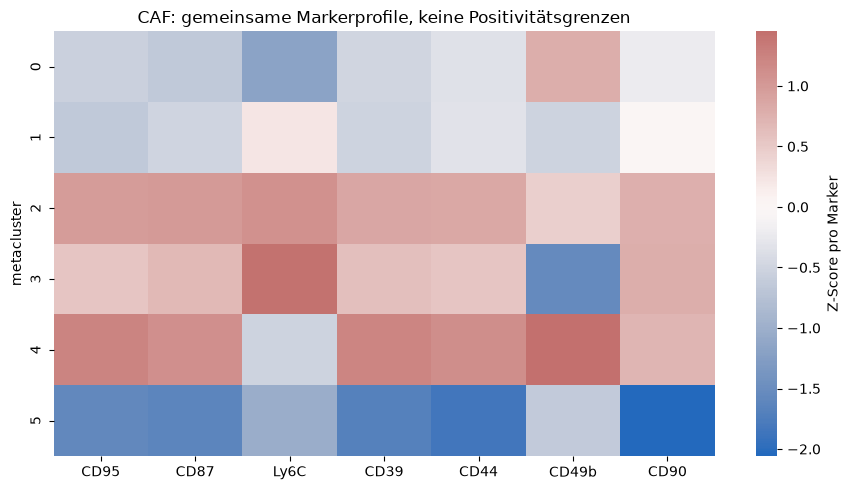

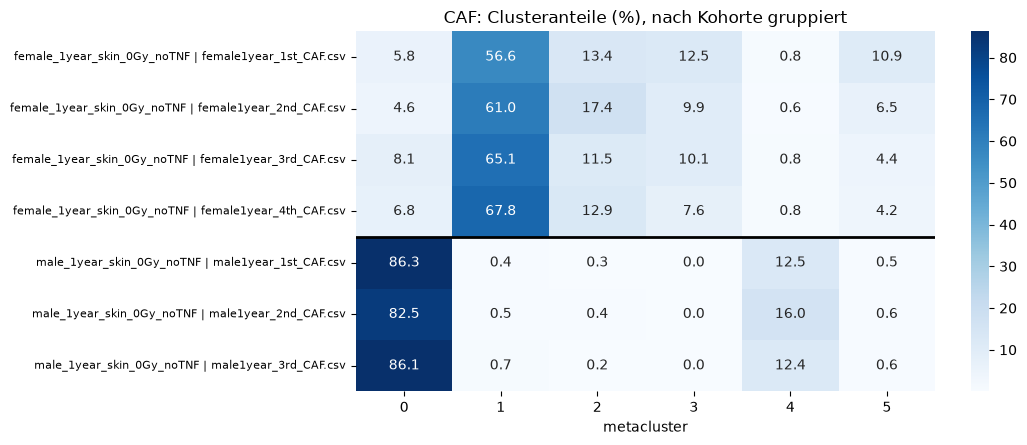

/home/tom/anaconda3/envs/fibro-flowsom/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


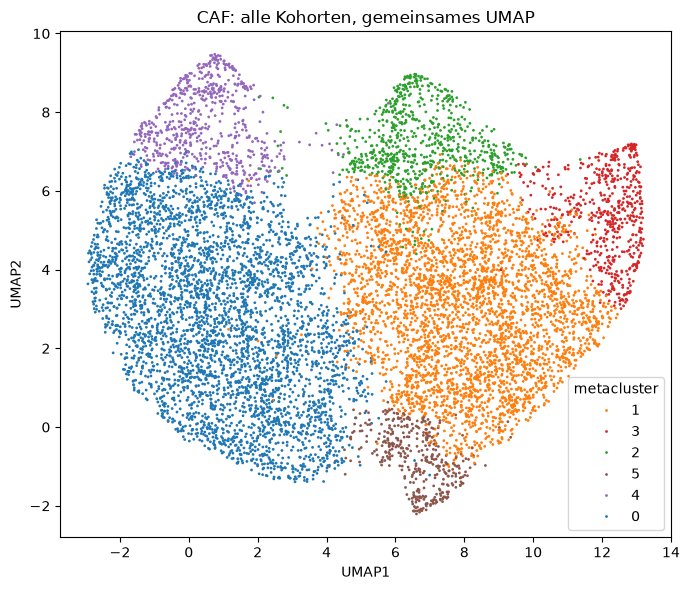

In [14]:
for panel,result in results.items():
    folder=RUN_DIR/panel
    events=result["annotated"]
    transformed=result["transformed"].copy()
    transformed["metacluster"]=events.metacluster.to_numpy()
    meta=file_index[file_index.panel==panel].sort_values(["cohort","filename"])
    markers=result["markers"]; report=markers+["CD90"]
    labels=range(N_METACLUSTERS)
    counts=pd.crosstab(events.filename,events.metacluster).reindex(index=meta.filename,columns=labels,fill_value=0)
    counts.index.name="filename"
    pct=counts.div(counts.sum(axis=1),axis=0)*100
    counts.to_csv(folder/"counts_per_file.csv")
    pct.to_csv(folder/"percentages_per_file.csv")
    overview=meta[["cohort","filename"]].merge(pct.reset_index(),on="filename",validate="one_to_one")
    overview.to_csv(folder/"percentages_with_cohorts.csv",index=False)
    display(overview.round(2))
    percentages=[]
    for i,r in enumerate(meta.itertuples(),1):
        target=folder/"individual_files"/f"file_{i:02d}"; target.mkdir(parents=True,exist_ok=True)
        g=events[events.filename==r.filename]
        g.to_csv(target/"events_raw_with_clusters.csv.gz",index=False,compression="gzip")
        (target/"source_filename.txt").write_text(r.filename,encoding="utf-8")
        for stat in ["mean","median"]:
            g.groupby("metacluster")[report].agg(stat).reindex(labels).to_csv(target/f"raw_{stat}.csv")
        transformed[transformed.filename==r.filename].groupby("metacluster")[report].median().reindex(labels).to_csv(target/"transformed_median.csv")
        t=pd.DataFrame({"metacluster":list(labels),"count":counts.loc[r.filename].to_numpy(),"percentage":pct.loc[r.filename].to_numpy()})
        t["filename"]=r.filename; t["cohort"]=r.cohort; t["panel"]=panel
        t["total_cells"]=len(g); t["run_id"]=RUN_ID
        t.to_csv(target/"cluster_percentages.csv",index=False); percentages.append(t)
    long=pd.concat(percentages,ignore_index=True)
    long.to_csv(folder/"all_file_percentages.csv",index=False)
    result["percentages"]=long
    heat=transformed.groupby("metacluster")[report].median().reindex(labels)
    heat.to_csv(folder/"cluster_marker_medians.csv")
    z=(heat-heat.mean())/heat.std(ddof=0).replace(0,np.nan)
    fig,ax=plt.subplots(figsize=(9,5))
    sns.heatmap(z.fillna(0),cmap="vlag",center=0,ax=ax,cbar_kws={"label":"Z-Score pro Marker"})
    ax.set_title(f"{panel}: gemeinsame Markerprofile, keine Positivitätsgrenzen")
    fig.tight_layout(); fig.savefig(folder/"shared_marker_heatmap.png",dpi=180); plt.show()
    fig,ax=plt.subplots(figsize=(11,max(4,len(pct)*.65)))
    sns.heatmap(pct,annot=True,fmt=".1f",cmap="Blues",ax=ax)
    ylabels=[textwrap.fill(f"{r.cohort} | {r.filename}",80) for r in meta.itertuples()]
    ax.set_yticklabels(ylabels,rotation=0,fontsize=8)
    boundaries=meta.cohort.ne(meta.cohort.shift()).to_numpy().nonzero()[0]
    for b in boundaries[1:]: ax.axhline(b,color="black",lw=2)
    ax.set_title(f"{panel}: Clusteranteile (%), nach Kohorte gruppiert"); ax.set_ylabel("")
    fig.tight_layout(); fig.savefig(folder/"percentages_grouped_by_cohort.png",dpi=180); plt.show()
    rng=np.random.default_rng(SEED)
    n_each=min(int(events.groupby("filename").size().min()),max(1,UMAP_MAX_CELLS//len(meta)))
    idx=np.concatenate([rng.choice(g.index.to_numpy(),n_each,replace=False) for _,g in events.groupby("filename",sort=True)])
    coords=UMAP(n_neighbors=min(30,len(idx)-1),min_dist=.3,random_state=SEED).fit_transform(transformed.loc[idx,markers].to_numpy())
    emb=events.loc[idx,["filename","cohort","event_id","metacluster"]].copy()
    emb["UMAP1"]=coords[:,0]; emb["UMAP2"]=coords[:,1]
    emb.to_csv(folder/"shared_umap_subset.csv",index=False); result["embedding"]=emb
    palette=dict(zip(map(str,labels),sns.color_palette("tab10",N_METACLUSTERS)))
    result["palette"]=palette
    fig,ax=plt.subplots(figsize=(7,6))
    sns.scatterplot(data=emb,x="UMAP1",y="UMAP2",hue=emb.metacluster.astype(str),palette=palette,s=4,linewidth=0,ax=ax)
    ax.set_title(f"{panel}: alle Kohorten, gemeinsames UMAP")
    fig.tight_layout(); fig.savefig(folder/"shared_umap.png",dpi=180); plt.show()
    params=dict(run_id=RUN_ID,signal=SIGNAL,seed=SEED,markers=markers,cd90_used_for_clustering=False,
        n_metaclusters=N_METACLUSTERS,pilot_cofactor=PILOT_COFACTOR,cofactors=COFACTORS[panel],
        already_transformed=ALREADY_TRANSFORMED,train_per_file=n_train,
        versions={p:importlib.metadata.version(p) for p in ["flowsom","anndata","numpy","pandas","umap-learn"]})
    params["train_per_file"]=min(MAX_TRAIN_PER_SAMPLE,int(events.groupby("filename").size().min()))
    (folder/"parameters.json").write_text(json.dumps(params,indent=2),encoding="utf-8")


## 5. Übersichtlich gruppierte UMAPs
Zuerst die Kohorten nebeneinander auf derselben Karte. Danach **eine separate Abbildung pro Kohorte** mit Dateinamen als Titeln. Einheitliche Achsen und Clusterfarben. Dies zeigt Lage und Verteilung, ist aber kein Signifikanztest.

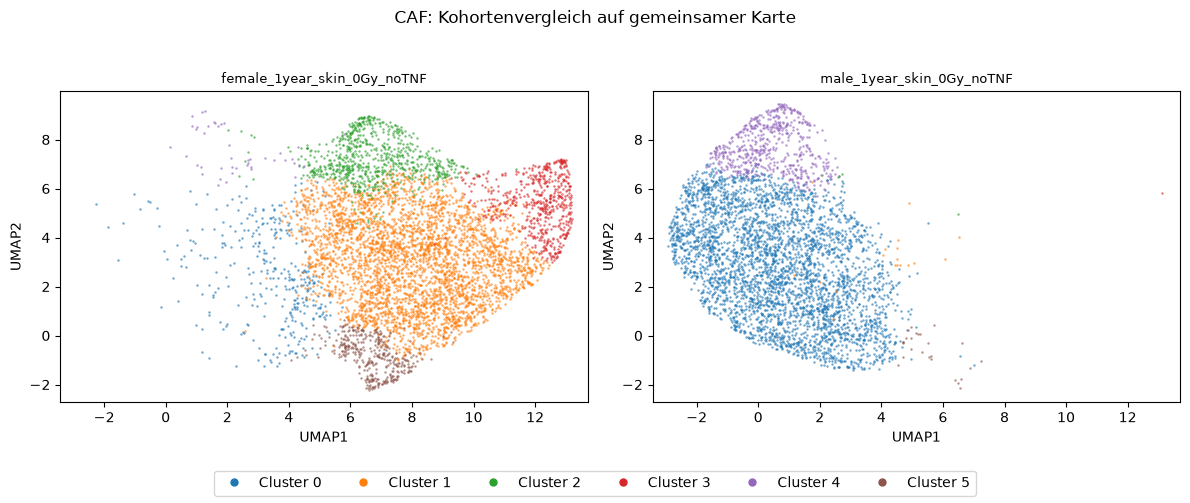

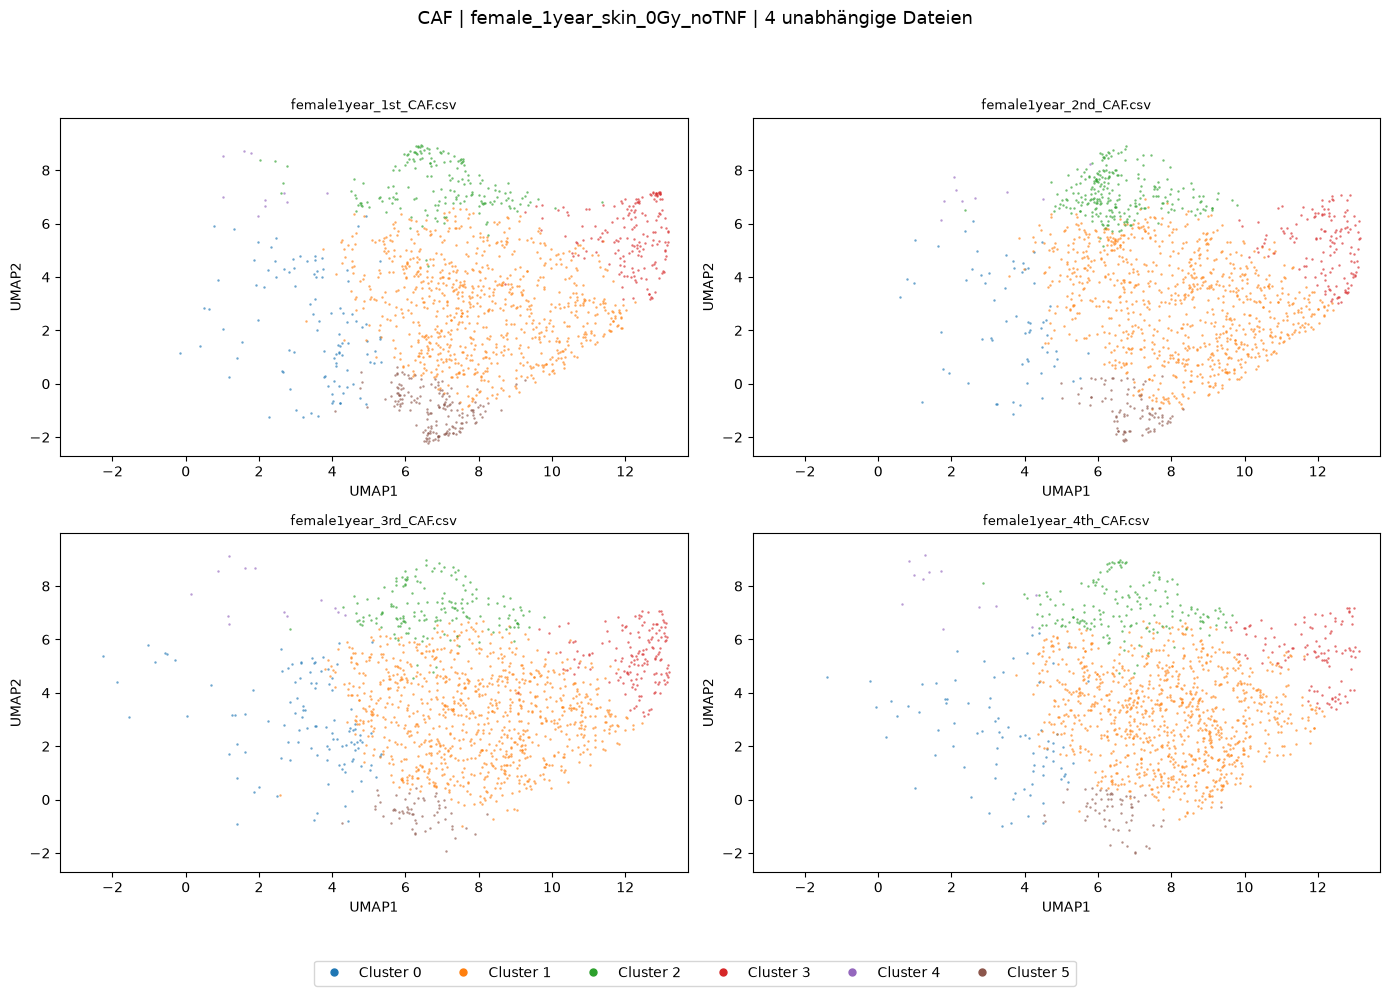

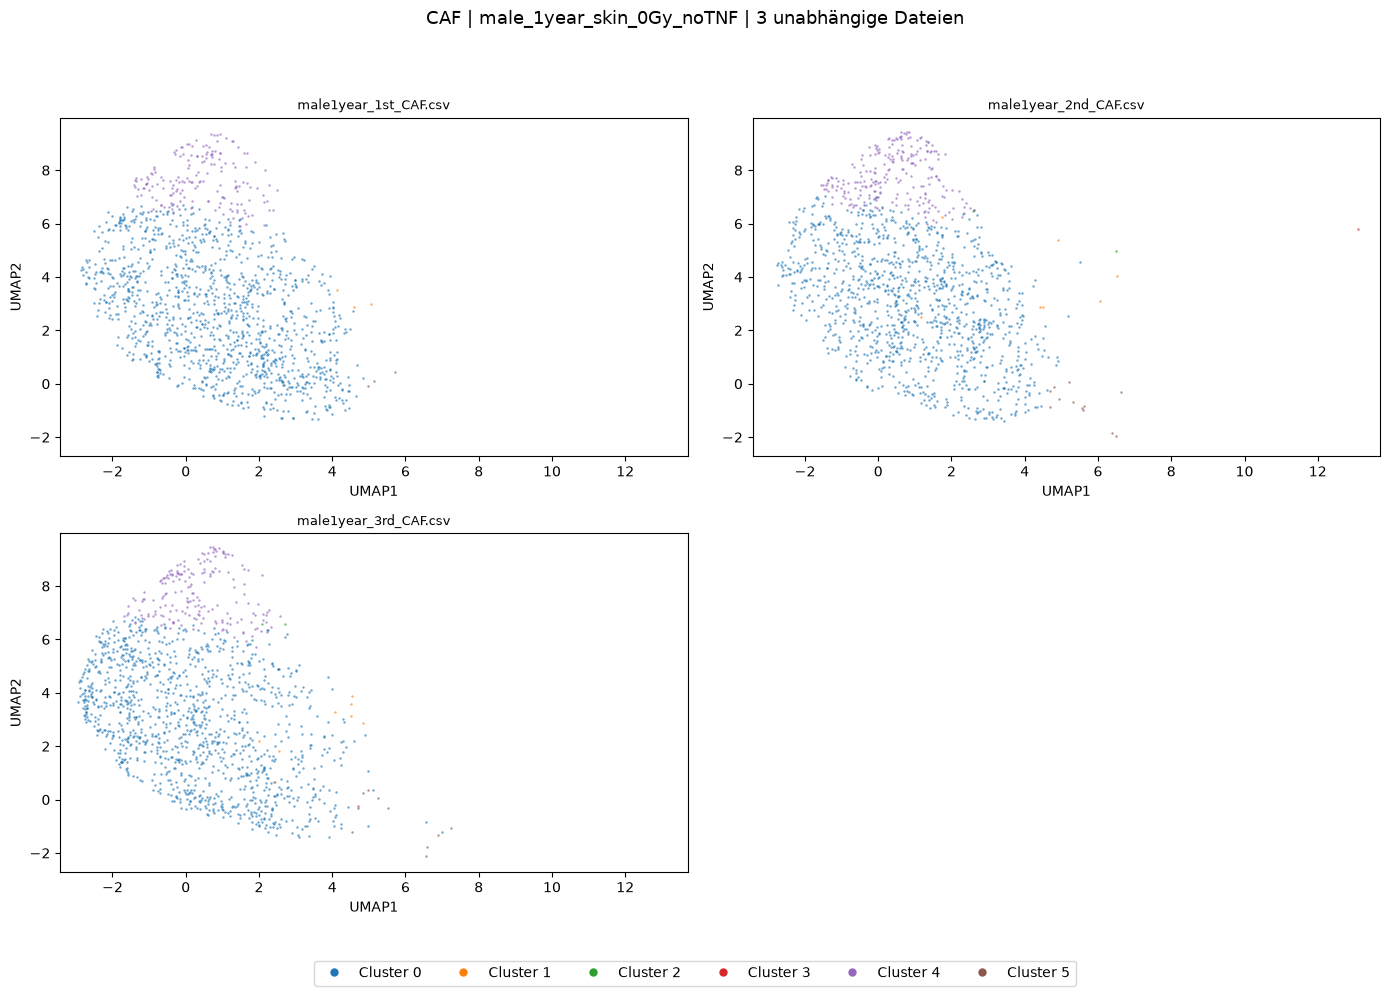

In [15]:
from matplotlib.lines import Line2D
for panel,result in results.items():
    emb=result["embedding"]; palette=result["palette"]; folder=RUN_DIR/panel
    cohorts=sorted(emb.cohort.unique())
    xlim=(emb.UMAP1.min()-.5,emb.UMAP1.max()+.5)
    ylim=(emb.UMAP2.min()-.5,emb.UMAP2.max()+.5)
    legend=[Line2D([0],[0],marker="o",linestyle="",color=palette[str(i)],label=f"Cluster {i}",markersize=5) for i in range(N_METACLUSTERS)]
    def draw(ax,g,title):
        for cl in range(N_METACLUSTERS):
            q=g[g.metacluster.astype(int)==cl]
            ax.scatter(q.UMAP1,q.UMAP2,s=3,c=[palette[str(cl)]],linewidths=0,alpha=.65)
        ax.set(xlim=xlim,ylim=ylim,xlabel="UMAP1",ylabel="UMAP2")
        ax.set_title(textwrap.fill(title,55),fontsize=9)
    fig,axes=plt.subplots(1,len(cohorts),figsize=(6*len(cohorts),5),squeeze=False)
    for ax,cohort in zip(axes.flat,cohorts): draw(ax,emb[emb.cohort==cohort],cohort)
    fig.suptitle(f"{panel}: Kohortenvergleich auf gemeinsamer Karte")
    fig.legend(handles=legend,loc="lower center",ncol=N_METACLUSTERS)
    fig.tight_layout(rect=[0,.08,1,.95]); fig.savefig(folder/"umap_cohorts.png",dpi=180); plt.show()
    for k,cohort in enumerate(cohorts,1):
        names=sorted(emb.loc[emb.cohort==cohort,"filename"].unique())
        cols=min(PLOT_COLUMNS,len(names)); rows=math.ceil(len(names)/cols)
        fig,axes=plt.subplots(rows,cols,figsize=(7*cols,5*rows),squeeze=False)
        for ax,name in zip(axes.flat,names): draw(ax,emb[emb.filename==name],name)
        for ax in list(axes.flat)[len(names):]: ax.set_visible(False)
        fig.suptitle(textwrap.fill(f"{panel} | {cohort} | {len(names)} unabhängige Dateien",110),fontsize=13)
        fig.legend(handles=legend,loc="lower center",ncol=N_METACLUSTERS)
        fig.tight_layout(rect=[0,.06,1,.94]); fig.savefig(folder/f"umap_individuals_cohort_{k}.png",dpi=180); plt.show()


## 6. Statistik aus den individuellen Prozent-CSVs
Ohne biological_id: jede CSV zählt als unabhängige biologische Replikation. Setze CONFIRM_INDEPENDENT_FILES=True nur nach eigener Prüfung. Bei gepaarten Behandlungen/technischen Wiederholungen gilt dieser Test nicht. Beide Kohorten und mindestens zwei Dateien pro Gruppe sind erforderlich; ungleiche n erlaubt.

Zweiseitiger unabhängiger Permutationstest der mittleren Prozentdifferenz (B−A), exakt bis 100.000 Zuordnungen, sonst Monte Carlo. Austauschbarkeit unter der Nullhypothese vorausgesetzt; keine Batchkorrektur. Mittel ± Stichproben-SD (ddof=1), BH über alle Cluster dieses Panels und dieses Vergleichs. Bei mehreren geplanten Kontrasten muss die Testfamilie entsprechend erweitert werden. Kleine n begrenzen die Auflösung: bei 4 gegen 4 minimaler üblicher zweiseitiger exakter p-Wert 2/70; bei 3 gegen 4 2/35. Nichtsignifikant bedeutet nicht gleich. Clusteranteile sind kompositionell, keine absoluten Zellzahlen. Keine Bestätigung eines Subtyps durch p-Wert.

Diese Zelle kann nach Imports/Konfiguration in einem neuen Kernel laufen: STATS_RUN_DIR auf den gewünschten Laufordner setzen. Sie liest ausschließlich individuelle cluster_percentages.csv des gewählten Laufs.
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html


,cohort,metacluster,n,mean,std
0,female_1year_skin_0Gy_noTNF,0,4,6.338218,1.465543
1,female_1year_skin_0Gy_noTNF,1,4,62.637151,4.863101
2,female_1year_skin_0Gy_noTNF,2,4,13.786037,2.561537
3,female_1year_skin_0Gy_noTNF,3,4,10.009625,1.991971
4,female_1year_skin_0Gy_noTNF,4,4,0.742065,0.126657
5,female_1year_skin_0Gy_noTNF,5,4,6.486904,3.115121
6,male_1year_skin_0Gy_noTNF,0,3,84.940171,2.143606
7,male_1year_skin_0Gy_noTNF,1,3,0.550473,0.150552
8,male_1year_skin_0Gy_noTNF,2,3,0.301736,0.093573
9,male_1year_skin_0Gy_noTNF,3,3,0.011787,0.008366


,panel,metacluster,cohort_A,cohort_B,n_A,n_B,mean_A,std_A,mean_B,std_B,difference_percentage_points,p_value,method,p_adjusted_BH,reject_FDR_0_05
0,CAF,0,female_1year_skin_0Gy_noTNF,male_1year_skin_0Gy_noTNF,4,3,6.338218,1.465543,84.940171,2.143606,78.601953,0.057143,exact,0.057143,False
1,CAF,1,female_1year_skin_0Gy_noTNF,male_1year_skin_0Gy_noTNF,4,3,62.637151,4.863101,0.550473,0.150552,-62.086677,0.057143,exact,0.057143,False
2,CAF,2,female_1year_skin_0Gy_noTNF,male_1year_skin_0Gy_noTNF,4,3,13.786037,2.561537,0.301736,0.093573,-13.484301,0.057143,exact,0.057143,False
3,CAF,3,female_1year_skin_0Gy_noTNF,male_1year_skin_0Gy_noTNF,4,3,10.009625,1.991971,0.011787,0.008366,-9.997838,0.057143,exact,0.057143,False
4,CAF,4,female_1year_skin_0Gy_noTNF,male_1year_skin_0Gy_noTNF,4,3,0.742065,0.126657,13.619384,2.027573,12.877319,0.057143,exact,0.057143,False
5,CAF,5,female_1year_skin_0Gy_noTNF,male_1year_skin_0Gy_noTNF,4,3,6.486904,3.115121,0.576448,0.034451,-5.910456,0.057143,exact,0.057143,False


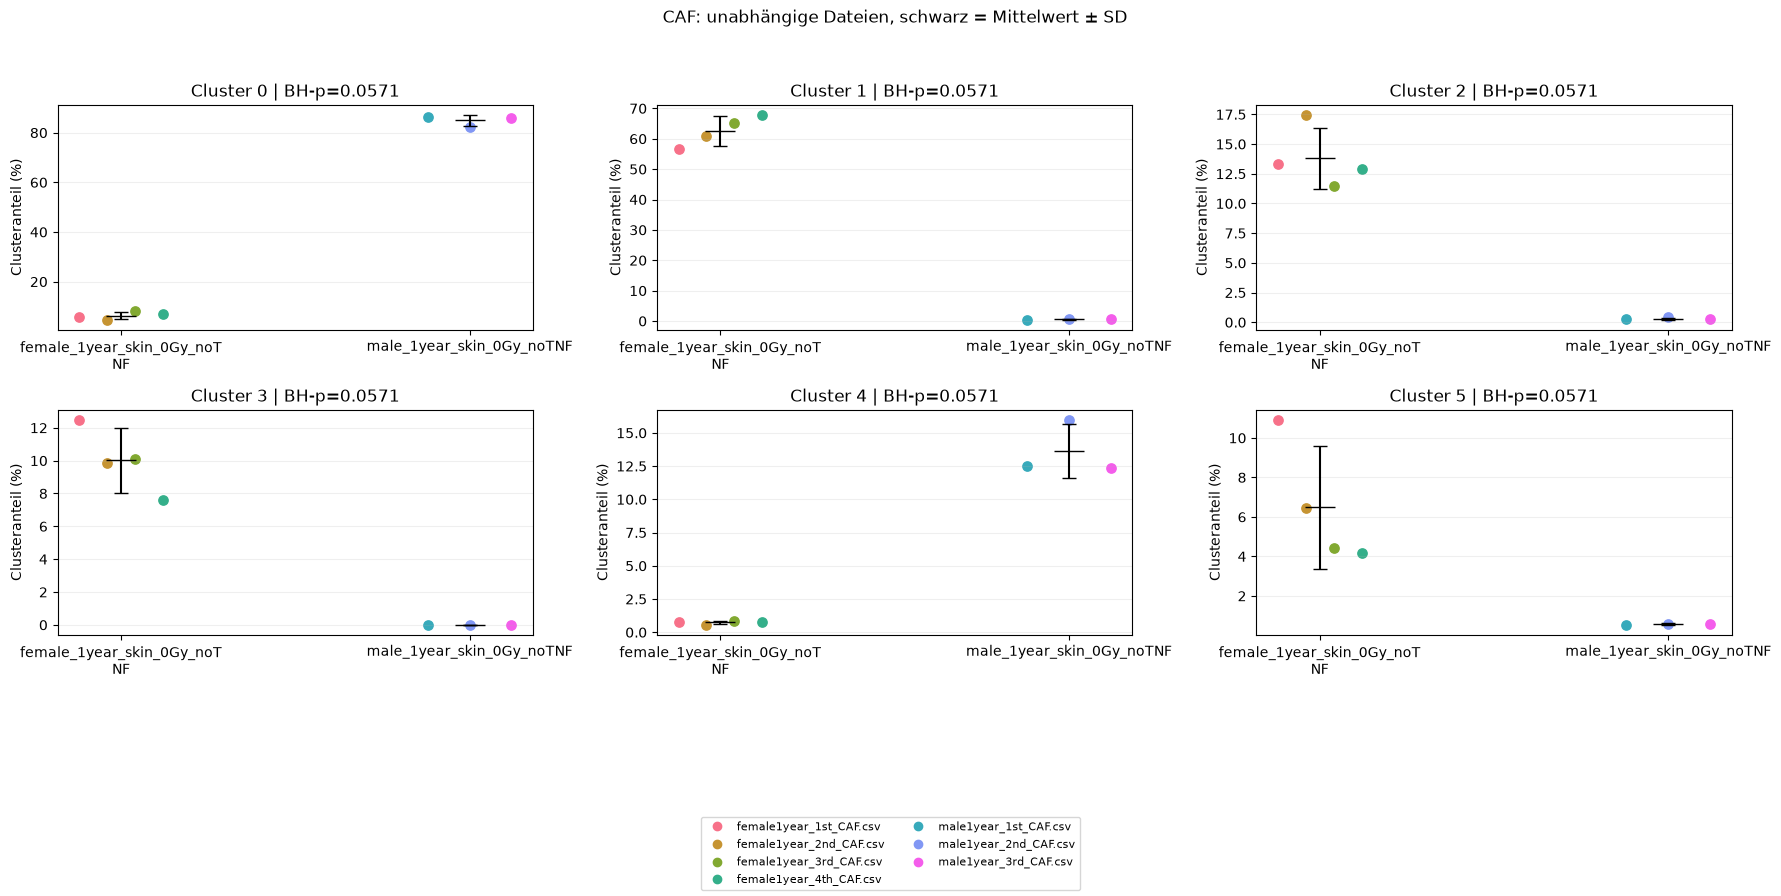

In [16]:
from scipy.stats import permutation_test
from statsmodels.stats.multitest import multipletests
STATS_RUN_DIR = RUN_DIR  # alternativ Path(".../gewünschter_Laufordner")
assert CONFIRM_INDEPENDENT_FILES, "Bestätige unabhängige biologische Dateien in der Konfiguration."
assert COHORT_A != COHORT_B
for panel in PANELS:
    folder=STATS_RUN_DIR/panel
    paths=sorted((folder/"individual_files").glob("*/cluster_percentages.csv"))
    if not paths: continue
    tabs=[pd.read_csv(p,keep_default_na=False) for p in paths]
    needed={"filename","cohort","metacluster","percentage","run_id"}
    for p,t in zip(paths,tabs):
        assert needed<=set(t.columns), f"Ungültiges Schema: {p}"
        assert t.filename.nunique()==1 and not t.metacluster.duplicated().any()
        assert np.isclose(pd.to_numeric(t.percentage).sum(),100,atol=.01)
    d=pd.concat(tabs,ignore_index=True)
    assert d.run_id.nunique()==1, "Keine unterschiedlichen Modellläufe mischen."
    assert not d.duplicated(["filename","metacluster"]).any()
    assert len(set(d.groupby("filename").metacluster.apply(frozenset)))==1
    assert d.groupby("filename").cohort.nunique().eq(1).all()
    d=d[d.cohort.isin([COHORT_A,COHORT_B])].copy()
    if d.cohort.nunique()!=2:
        print(panel,"Statistik übersprungen: COHORT_A/B müssen exakt den Ordnernamen entsprechen."); continue
    d["percentage"]=pd.to_numeric(d.percentage,errors="raise")
    assert d.percentage.between(0,100).all()
    summary=d.groupby(["cohort","metacluster"]).percentage.agg(n="size",mean="mean",std="std").reset_index()
    assert summary.n.ge(2).all(), "Mindestens zwei unabhängige Dateien pro Kohorte."
    summary.to_csv(folder/"cohort_mean_std.csv",index=False)
    rows=[]
    for cl,g in d.groupby("metacluster",sort=True):
        a=g.loc[g.cohort==COHORT_A,"percentage"].to_numpy(float)
        b=g.loc[g.cohort==COHORT_B,"percentage"].to_numpy(float)
        exact=math.comb(len(a)+len(b),len(a))<=100000
        test=permutation_test((a,b),lambda x,y: np.mean(y)-np.mean(x),vectorized=False,
             permutation_type="independent",alternative="two-sided",
             n_resamples=np.inf if exact else 99999,random_state=SEED)
        rows.append(dict(panel=panel,metacluster=cl,cohort_A=COHORT_A,cohort_B=COHORT_B,
            n_A=len(a),n_B=len(b),mean_A=a.mean(),std_A=a.std(ddof=1),mean_B=b.mean(),
            std_B=b.std(ddof=1),difference_percentage_points=b.mean()-a.mean(),p_value=test.pvalue,
            method="exact" if exact else "Monte Carlo"))
    stats=pd.DataFrame(rows)
    stats["p_adjusted_BH"]=multipletests(stats.p_value,method="fdr_bh")[1]
    stats["reject_FDR_0_05"]=stats.p_adjusted_BH<.05
    stats.to_csv(folder/"cluster_comparison_statistics.csv",index=False)
    display(summary); display(stats)
    clusters=sorted(d.metacluster.unique()); cols=min(3,len(clusters)); nr=math.ceil(len(clusters)/cols)
    fig,axes=plt.subplots(nr,cols,figsize=(6*cols,4.5*nr),squeeze=False)
    names=sorted(d.filename.unique()); colors=dict(zip(names,sns.color_palette("husl",len(names))))
    for ax,cl in zip(axes.flat,clusters):
        for i,cohort in enumerate([COHORT_A,COHORT_B]):
            part=d[(d.cohort==cohort)&(d.metacluster==cl)].sort_values("filename")
            offsets=np.linspace(-.12,.12,len(part))
            for off,row in zip(offsets,part.itertuples()):
                ax.scatter(i+off,row.percentage,color=colors[row.filename],s=45)
            s=summary[(summary.cohort==cohort)&(summary.metacluster==cl)].iloc[0]
            ax.errorbar(i,s["mean"],yerr=s["std"],fmt="_",markersize=22,capsize=5,color="black")
        p=stats.loc[stats.metacluster==cl,"p_adjusted_BH"].iloc[0]
        ax.set_title(f"Cluster {cl} | BH-p={p:.3g}")
        ax.set_xticks([0,1],[textwrap.fill(COHORT_A,25),textwrap.fill(COHORT_B,25)])
        ax.set_ylabel("Clusteranteil (%)"); ax.grid(axis="y",alpha=.2)
    for ax in list(axes.flat)[len(clusters):]: ax.set_visible(False)
    handles=[plt.Line2D([0],[0],marker="o",linestyle="",color=colors[name],label=textwrap.fill(name,65)) for name in names]
    fig.suptitle(f"{panel}: unabhängige Dateien, schwarz = Mittelwert ± SD")
    fig.legend(handles=handles,loc="lower center",ncol=2,fontsize=8)
    fig.tight_layout(rect=[0,.22,1,.95]); fig.savefig(folder/"statistics_grouped.png",dpi=180); plt.show()
